In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
import seaborn as sns
import os
from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

In [5]:
data = pd.read_csv('all_stocks_5yr.csv', delimiter=',', on_bad_lines='skip')
print(data.shape)
print(data.sample(10))

(619040, 7)
              date    open    high      low    close    volume  Name
97596   2015-02-23   83.90   83.98   83.140   83.490   5180033   CAT
328332  2017-05-31   18.38   18.95   18.310   18.760  25332138   KMI
481217  2015-11-05  179.27  180.51  178.950  179.970    199710    RE
70807   2014-11-28  570.00  583.00  566.076  577.710    121169   AZO
96621   2016-04-08   84.11   84.63   82.640   83.000   1408523   CAH
548513  2014-08-01   37.10   37.56   37.000   37.050  11397588   TSN
226383  2013-12-23   52.80   52.87   52.370   52.490    904547   FIS
438212  2015-10-06   53.99   54.50   53.660   54.090   2210981  PCAR
113318  2014-03-17   34.37   34.72   34.260   34.375   1136438   CHD
425460  2014-09-10   17.27   17.51   17.200   17.465   1652054  NWSA


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


In [6]:
data['date'] = pd.to_datetime(data['date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    619040 non-null  datetime64[ns]
 1   open    619029 non-null  float64       
 2   high    619032 non-null  float64       
 3   low     619032 non-null  float64       
 4   close   619040 non-null  float64       
 5   volume  619040 non-null  int64         
 6   Name    619040 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 33.1+ MB


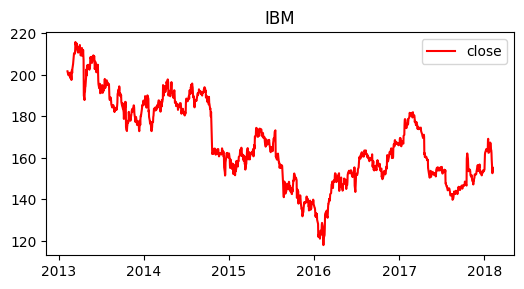

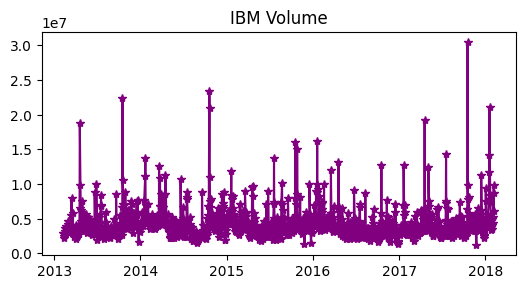

In [21]:
#companies = ['AAPL', 'AMD', 'FB', 'GOOGL', 'AMZN', 'NVDA', 'EBAY', 'CSCO', 'IBM']
companies = ['IBM']
plt.figure(figsize=(15, 8))
for index, company in enumerate(companies, 1):
    plt.subplot(3, 3, index)
    c = data[data['Name'] == company]
    plt.plot(c['date'], c['close'], c="r", label="close", marker="")
    #plt.plot(c['date'], c['open'], c="g", label="open", marker="^")
    plt.title(company)
    plt.legend()
    plt.tight_layout()


#Volume is the number of IBM (or any company) shares traded during a given period (usually one day)
plt.figure(figsize=(15, 8))
for index, company in enumerate(companies, 1):
    plt.subplot(3, 3, index)
    c = data[data['Name'] == company]
    plt.plot(c['date'], c['volume'], c='purple', marker='*')
    plt.title(f"{company} Volume")
    plt.tight_layout()

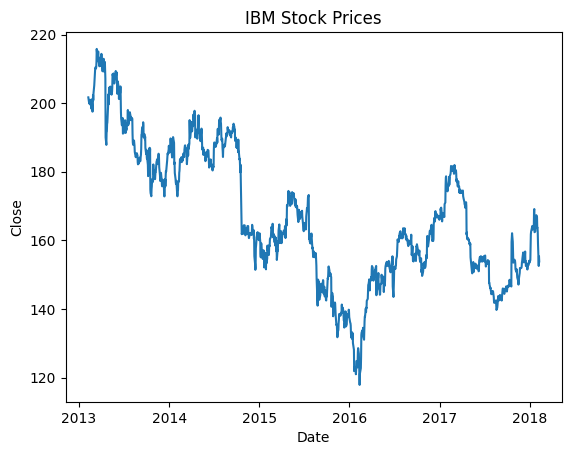

In [22]:
IBM = data[data['Name'] == 'IBM']
prediction_range = IBM.loc[(IBM ['date'] > datetime(2013,1,1))
 & (IBM ['date']<datetime(2018,1,1))]
plt.plot(IBM ['date'],IBM ['close'])
plt.xlabel("Date")
plt.ylabel("Close")
plt.title("IBM Stock Prices")
plt.show()

In [23]:
close_data = IBM.filter(['close'])
dataset = close_data.values
training = int(np.ceil(len(dataset) * .95))
print(training)

1197


In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

train_data = scaled_data[0:int(training), :]
# prepare feature and labels
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

In [25]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(x_train.shape[1], 1)))
model.add(keras.layers.LSTM(units=128, return_sequences=True))
model.add(keras.layers.Dropout(0.2))
model.add(keras.layers.LSTM(units=64))
model.add(keras.layers.Dropout(0.2))
model.add(keras.layers.Dense(32, activation="relu"))
model.add(keras.layers.Dense(1))
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 60, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,081 (461.25 KB)

 Trainable params: 118,081 (461.25 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(optimizer='adam',
              loss='mean_squared_error')
history = model.fit(x_train,
                    y_train,
                    epochs=10)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 139ms/step - loss: 0.0310
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - loss: 0.0043
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0037
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 0.0032
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0030
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - loss: 0.0032
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - loss: 0.0027
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - loss: 0.0029
Epoch 9/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 0.0025
Epoch 10/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step - loss: 0.0021


In [27]:
test_data = scaled_data[training - 60:, :]
x_test = []
y_test = dataset[training:, :]
for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

mse = np.mean(((predictions - y_test) ** 2))
rmse = np.sqrt(mse)

print("MSE", mse)
print("RMSE", np.sqrt(mse))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 331ms/step
MSE 16.00905668879774
RMSE 4.001131925942675


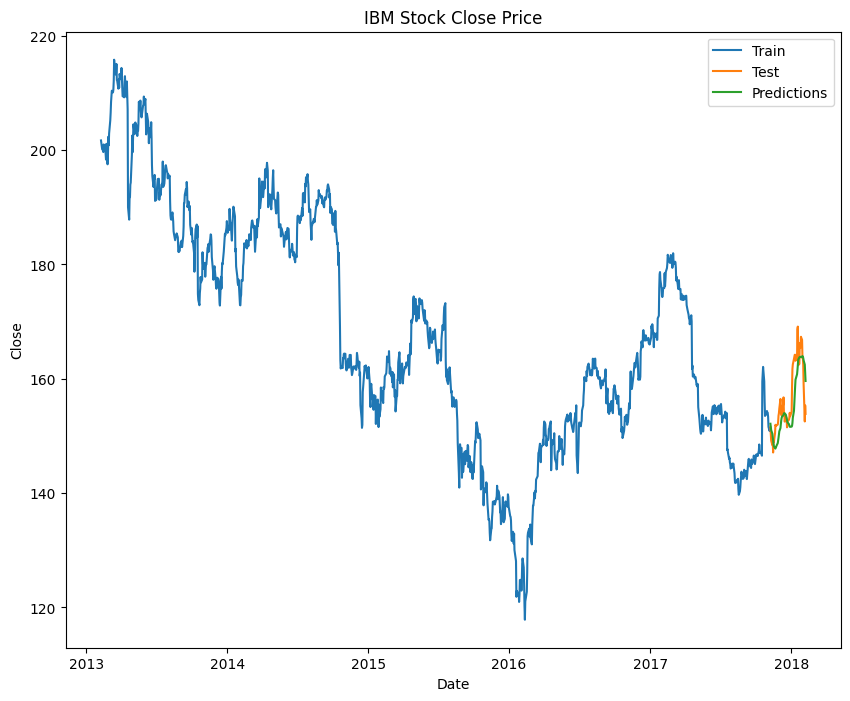

In [28]:
train = IBM[:training]
test = IBM[training:]
test['Predictions'] = predictions

plt.figure(figsize=(10, 8))
plt.plot(train['date'], train['close'])
plt.plot(test['date'], test[['close', 'Predictions']])
plt.title('IBM Stock Close Price')
plt.xlabel('Date')
plt.ylabel("Close")
plt.legend(['Train', 'Test', 'Predictions'])